# 06 · When EM Struggles

The honest operator's guide. EM is guaranteed to climb the log-likelihood every
iteration — but only to a **local** optimum, and only for the number of components you
told it to find. This notebook shows the characteristic failure modes and the standard
mitigations, then distills a decision framework.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def _repo_root() -> Path:
    here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").exists():
            return cand
    return here


ROOT = _repo_root()
FIG_DIR = ROOT / "outputs" / "figures"
DATA_DIR = ROOT / "outputs" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def savefig(fig, name):
    """Save a matplotlib figure as outputs/figures/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"figure -> {path.relative_to(ROOT)}")
    return path


def savejson(name, obj):
    """Save textual/numerical content as outputs/data/<name>.json."""
    path = DATA_DIR / f"{name}.json"
    path.write_text(json.dumps(_jsonable(obj), indent=2))
    print(f"data   -> {path.relative_to(ROOT)}")
    return path


plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)


## Local optima: same data, different answers

Six well-separated clusters. EM from different random starts lands in different basins:
when the random seeding happens to drop two centers in one true cluster and none in
another, EM converges to a confidently wrong solution. Here are the final
log-likelihoods of 40 single-start fits.


best=-4984  worst=-5655  spread=671
reached the best basin: 42% of random starts
figure -> outputs/figures/nb06_restart_spread.png


PosixPath('/workspaces/expectation_maximization_101/outputs/figures/nb06_restart_spread.png')

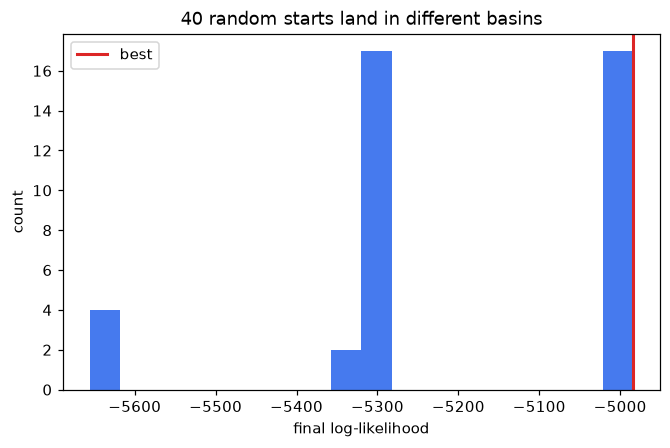

In [2]:
from src.datasets.mixtures import make_blobs
from src.em.gmm import GaussianMixtureEM

ang = np.linspace(0, 2 * np.pi, 6, endpoint=False)
centers = np.c_[7 * np.cos(ang), 7 * np.sin(ang)]
Xo, _, _ = make_blobs(1200, centers, cluster_std=0.8, seed=3)
K = 6
GAP = 1.0   # a fit "reached the best basin" if within GAP of the best log-likelihood found


def fit_many(init, n=40):
    lls, labs = [], []
    for s in range(n):
        g = GaussianMixtureEM(K, n_init=1, init=init, random_state=s, max_iter=200).fit(Xo)
        lls.append(g.log_likelihood_)
        labs.append(g.labels_)
    return np.array(lls), labs


lls, labs = fit_many("random")
best, worst = float(lls.max()), float(lls.min())
best_i, worst_i = int(lls.argmax()), int(lls.argmin())
random_success = float(np.mean(lls >= best - GAP))
print(f"best={best:.0f}  worst={worst:.0f}  spread={best - worst:.0f}")
print(f"reached the best basin: {random_success:.0%} of random starts")

fig, ax = plt.subplots()
ax.hist(lls, bins=18, color="#2563eb", alpha=0.85)
ax.axvline(best, color="#dc2626", lw=2, label="best")
ax.set_xlabel("final log-likelihood"); ax.set_ylabel("count")
ax.set_title("40 random starts land in different basins")
ax.legend()
savefig(fig, "nb06_restart_spread")


figure -> outputs/figures/nb06_good_vs_bad.png


PosixPath('/workspaces/expectation_maximization_101/outputs/figures/nb06_good_vs_bad.png')

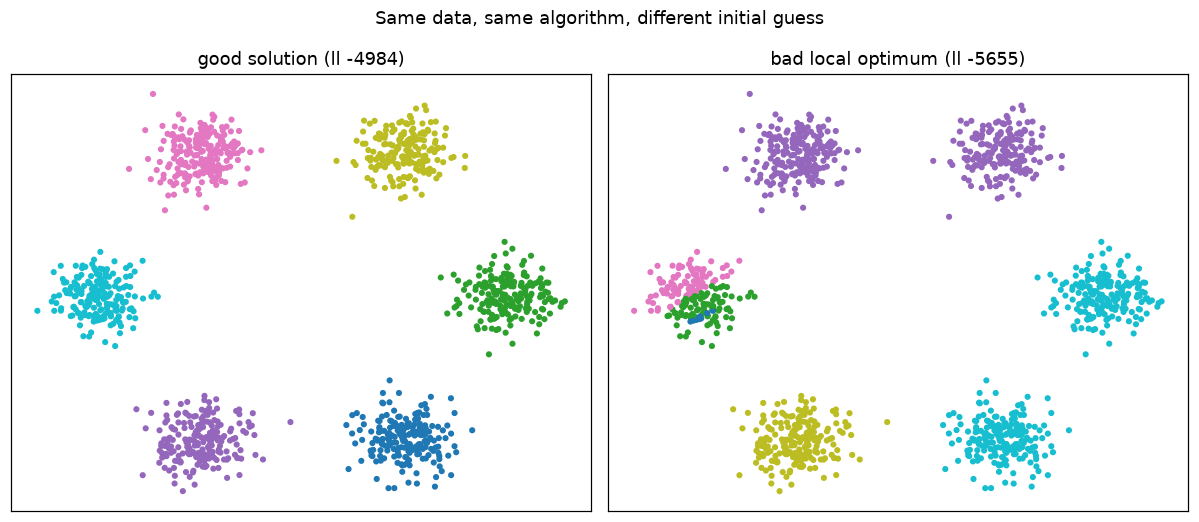

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].scatter(Xo[:, 0], Xo[:, 1], s=9, c=labs[best_i], cmap="tab10")
axes[0].set_title(f"good solution (ll {lls[best_i]:.0f})")
axes[1].scatter(Xo[:, 0], Xo[:, 1], s=9, c=labs[worst_i], cmap="tab10")
axes[1].set_title(f"bad local optimum (ll {lls[worst_i]:.0f})")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Same data, same algorithm, different initial guess")
fig.tight_layout()
savefig(fig, "nb06_good_vs_bad")


## Mitigation: k-means++ initialization + multiple restarts

k-means++ spreads the initial centers by squared-distance sampling, so it rarely drops
two seeds in the same cluster. Across 40 restarts it reaches the best basin far more
often than random seeding — and keeping the best of several restarts is what makes EM
reliable in practice.


reached the best basin  —  random: 42%   k-means++: 80%
figure -> outputs/figures/nb06_init_strategies.png
data   -> outputs/data/nb06_local_optima.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb06_local_optima.json')

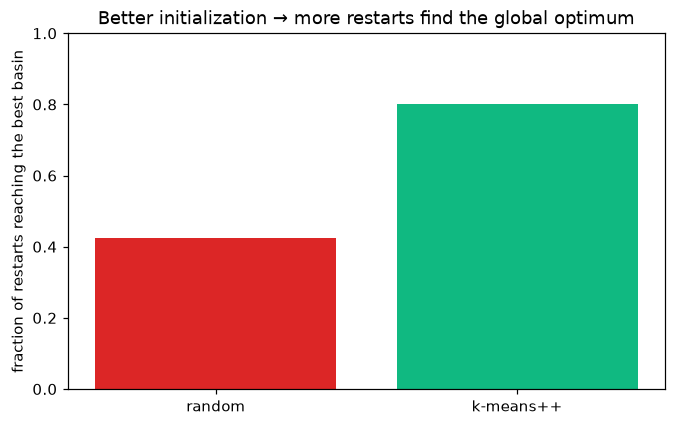

In [4]:
lls_kpp, _ = fit_many("kmeans++")
best_overall = float(max(lls.max(), lls_kpp.max()))
rand_succ = float(np.mean(lls >= best_overall - GAP))
kpp_succ = float(np.mean(lls_kpp >= best_overall - GAP))
print(f"reached the best basin  —  random: {rand_succ:.0%}   k-means++: {kpp_succ:.0%}")

fig, ax = plt.subplots()
ax.bar(["random", "k-means++"], [rand_succ, kpp_succ], color=["#dc2626", "#10b981"])
ax.set_ylabel("fraction of restarts reaching the best basin"); ax.set_ylim(0, 1)
ax.set_title("Better initialization → more restarts find the global optimum")
savefig(fig, "nb06_init_strategies")

savejson("nb06_local_optima", {
    "n_restarts": 40,
    "gap": GAP,
    "best_log_likelihood": best_overall,
    "random_init": {"success_fraction": rand_succ, "mean_ll": float(lls.mean()),
                    "worst_ll": worst},
    "kmeanspp_init": {"success_fraction": kpp_succ, "mean_ll": float(lls_kpp.mean()),
                      "worst_ll": float(lls_kpp.min())},
})


## Choosing the number of components with BIC / AIC

EM fits parameters for a *fixed* `k`; it will not tell you `k`. BIC and AIC score the
fitted log-likelihood against model complexity. On well-separated data they recover the
true component count.


best k by BIC = 3   by AIC = 6   (true = 3)
figure -> outputs/figures/nb06_model_selection.png
data   -> outputs/data/nb06_model_selection.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb06_model_selection.json')

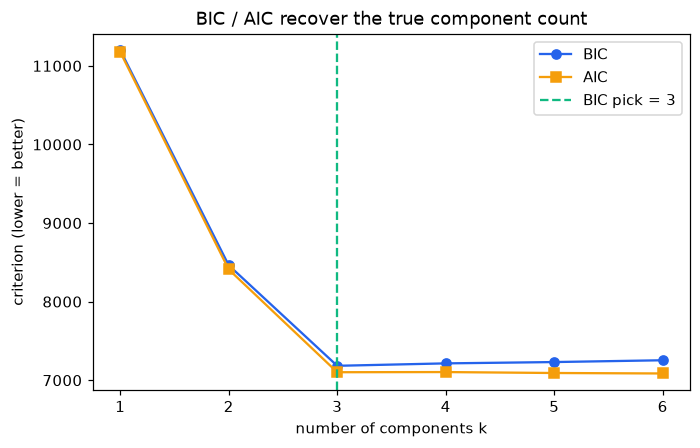

In [5]:
from src.diagnostics.model_selection import select_n_components

Xs, _, _ = make_blobs(900, [[-8, 0], [8, 0], [0, 9]], cluster_std=1.0, seed=9)
sel = select_n_components(Xs, range(1, 7), n_init=5, random_state=0)
ks = [r["k"] for r in sel["results"]]
bics = [r["bic"] for r in sel["results"]]
aics = [r["aic"] for r in sel["results"]]
print(f"best k by BIC = {sel['best_bic_k']}   by AIC = {sel['best_aic_k']}   (true = 3)")

fig, ax = plt.subplots()
ax.plot(ks, bics, marker="o", label="BIC", color="#2563eb")
ax.plot(ks, aics, marker="s", label="AIC", color="#f59e0b")
ax.axvline(sel["best_bic_k"], color="#10b981", ls="--", label=f"BIC pick = {sel['best_bic_k']}")
ax.set_xlabel("number of components k"); ax.set_ylabel("criterion (lower = better)")
ax.set_title("BIC / AIC recover the true component count"); ax.legend()
savefig(fig, "nb06_model_selection")
savejson("nb06_model_selection", sel)


## Other failure modes to know

- **The slow crawl.** Near convergence EM takes small steps; the log-likelihood still
  rises but tails off. Judge convergence on the *change* in log-likelihood, not a fixed
  iteration count.
- **Degenerate / collapsing components.** A component can shrink onto a single point,
  sending its covariance toward singular and the likelihood toward infinity. The library
  guards against this with **covariance regularization** (`reg_covar`, a small ridge on
  the diagonal).
- **Wrong k.** Too many components overfit (and invite collapse); too few underfit. Let
  BIC/AIC choose, and always sanity-check against separated-data recovery.


## Decision framework

| Situation | Use |
|---|---|
| Mixture of continuous groups | Gaussian mixture (GMM) |
| Categorical / survey responses | Latent class analysis (LCA) |
| Fast, round, roughly equal clusters | K-Means (hard EM) |
| Missing values | EM imputation |

**Always:** run multiple restarts with k-means++ initialization, regularize covariances,
judge convergence on the log-likelihood change, and pick the component count with a model
selection criterion (BIC/AIC).


In [6]:
savejson("nb06_narrative", {
    "title": "When EM Struggles",
    "failure_modes": [
        "Local optima — mitigate with k-means++ and multiple restarts.",
        "Slow crawl near convergence — judge on log-likelihood change.",
        "Component collapse / singular covariance — regularize (reg_covar).",
        "Wrong number of components — choose k with BIC/AIC.",
    ],
    "decision_framework": {
        "continuous_groups": "GMM",
        "categorical_responses": "LCA",
        "fast_round_clusters": "K-Means (hard EM)",
        "missing_values": "EM imputation",
        "always": "restarts + k-means++ + covariance regularization + model selection",
    },
    "figures": {
        "nb06_restart_spread": "Final log-likelihoods of 40 random starts.",
        "nb06_good_vs_bad": "A good solution vs a bad local optimum on the same data.",
        "nb06_init_strategies": "k-means++ reaches the best basin far more often than random.",
        "nb06_model_selection": "BIC/AIC recover the true component count.",
    },
})


data   -> outputs/data/nb06_narrative.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb06_narrative.json')